In [1]:
import crypten
import torch

import crypten.mpc as mpc
import crypten.communicator as comm 
from crypten.mpc import MPCTensor

import numpy as np
import math

#initialize crypten
crypten.init()
#Disables OpenMP threads -- needed by @mpc.run_multiprocess which uses fork
torch.set_num_threads(1)

In [2]:
def relu(x):
    y = (x + torch.sqrt(x**2)) / 2
    return y

In [3]:
def approx_relu(x_enc):
    x2_enc = x_enc / 10
    x2_enc = x2_enc.square()
    print(x2_enc.get_plain_text())
    y = x_enc + x2_enc.sqrt() * 10
    print(y.get_plain_text())
    y = y / 2
    return y

In [ ]:
def approx_relu(x_enc):
    # step1
    R1 = np.random.randint(1, 4096) # 实际由可信第三方TTP生成
    R1_rec = 1 / R1
    
    x_enc = x_enc + 1e-8
    xR1 = (x_enc * R1).get_plain_text() # reveal xR1
    
    # step2 
    y = xR1 % 13 # open 
    y = torch.where(xR1 < 0, y-13, y) # 调整成C++的取模符号随被除数
    tag = (y==0).to(torch.float)
    y = y + tag
    a = xR1 // 13 
    
    # step3
    y_enc = crypten.cryptensor(y)
    y_enc = y_enc + (y_enc.square()).sqrt()
    z = y_enc / 2
    
    # step4 
    b = 13*a / y # open
    b = crypten.cryptensor(b)
    r = z * b + z - tag
    
    z = r * R1_rec
    return z

In [85]:
@mpc.run_multiprocess(world_size=2)
def approx_relu_test(x):
    rank = comm.get().get_rank()
    x_enc = MPCTensor(x, ptype=crypten.mpc.arithmetic)
#     x_enc = x_enc + 1e-8
#     crypten.print(f"x_enc Rank {rank}: {x_enc.get_plain_text()}", in_order=True)
#     R1 = np.random.randint(1,4096)
#     R1_rec = 1 / R1
#     crypten.print(f"R1 Rank {rank}: {R1}", in_order=True)
    
#     # step1
    
#     xR1 = (x_enc * R1).get_plain_text() # reveal xR1 to src=0
#     crypten.print(f"xR1 Rank {rank}: {xR1}", in_order=True)
    
#     # step2
#     y = xR1 % 13 # open in src=0
#     y = torch.where(xR1 < 0, y-13, y) 
#     tag = (y==0).to(torch.float)
#     y = y + tag
#     a = xR1 // 13 # open in src=0
#     crypten.print(f"y Rank {rank}: {y}", in_order=True) # √
#     crypten.print(f"a Rank {rank}: {a}", in_order=True) # √
    
#     # step3
#     y_enc = crypten.cryptensor(y)
#     y_enc = y_enc + (y_enc.square()).sqrt()
#     z = y_enc / 2 
#     crypten.print(f"z Rank {rank}: {z.get_plain_text()}", in_order=True) 
    
#     # step4
    
#     b = 13*a / y # open in src=0 
#     crypten.print(f"b Rank {rank}: {b}", in_order=True) # √
#     b = crypten.cryptensor(b)
#     crypten.print(f"b_enc Rank {rank}: {b.get_plain_text()}", in_order=True) # √
#     r = z * b + z - tag
#     crypten.print(f"r Rank {rank}: {r.get_plain_text()}", in_order=True) 
    
#     z = r * R1_rec


#     # step1
#     R1 = np.random.randint(1, 4096) # 实际由可信第三方TTP生成
#     R1_rec = 1 / R1
    
#     x_enc = x_enc + 1e-8
#     xR1 = (x_enc * R1).get_plain_text() # reveal xR1
    
#     # step2 
#     y = xR1 % 13 # open 
#     y = torch.where(xR1 < 0, y-13, y) # 调整成C++的取模符号随被除数
#     tag = (y==0).to(torch.float)
#     y = y + tag
#     a = xR1 // 13 
    
#     # step3
#     y_enc = crypten.cryptensor(y)
#     y_enc = y_enc + (y_enc.square()).sqrt()
#     z = y_enc / 2
    
#     # step4 
#     b = 13*a / y # open
#     b = crypten.cryptensor(b)
#     r = z * b + z - tag
    
#     z = r * R1_rec
    

    # step1
    R1 = np.random.randint(1, 2048) / 100 # 实际由可信第三方TTP生成
    R1_rec = 1 / R1
    crypten.print(f"R1 Rank {rank}: {R1}", in_order=True) # √
    
    # step2
    x_enc = x_enc + 1e-5
    xR1_2 = ((x_enc * R1).square()).get_plain_text() # reveal (xR1)^2
    crypten.print(f"xR1_2 Rank {rank}: {xR1_2}", in_order=True) # √
    a = torch.sqrt(xR1_2)
    crypten.print(f"a Rank {rank}: {a}", in_order=True) # √
    
    # step3
    z = (x_enc + a*R1_rec) / 2

    
    crypten.print(f"z Rank {rank}: {z.get_plain_text()}", in_order=True) # √
    
    res = x.relu()
    crypten.print(f"res Rank {rank}: {res}", in_order=True)
    
    err, max_err = calc_relative_error(res,z.get_plain_text())
    crypten.print(f"err Rank {rank}: {err},{max_err}", in_order=True)
    # return z
    

tensor_size = (100,100)
x = torch.arange(start=0, end=100, step=0.01)
# x = torch.rand(1,1,*tensor_size)
print(x)
z = approx_relu_test(x)

tensor([0.0000e+00, 1.0000e-02, 2.0000e-02,  ..., 9.9970e+01, 9.9980e+01,
        9.9990e+01])
R1 Rank 0: 2.72
R1 Rank 1: 2.72
xR1_2 Rank 0: tensor([0.0000e+00, 7.4768e-04, 2.9449e-03,  ..., 7.3939e+04, 7.3954e+04,
        7.3968e+04])
xR1_2 Rank 1: tensor([0.0000e+00, 7.4768e-04, 2.9449e-03,  ..., 7.3939e+04, 7.3954e+04,
        7.3968e+04])
a Rank 0: tensor([0.0000e+00, 2.7344e-02, 5.4267e-02,  ..., 2.7192e+02, 2.7194e+02,
        2.7197e+02])
a Rank 1: tensor([0.0000e+00, 2.7344e-02, 5.4267e-02,  ..., 2.7192e+02, 2.7194e+02,
        2.7197e+02])
z Rank 0: tensor([0.0000e+00, 1.0025e-02, 1.9958e-02,  ..., 9.9970e+01, 9.9980e+01,
        9.9990e+01])
z Rank 1: tensor([0.0000e+00, 1.0025e-02, 1.9958e-02,  ..., 9.9970e+01, 9.9980e+01,
        9.9990e+01])
res Rank 0: tensor([0.0000e+00, 1.0000e-02, 2.0000e-02,  ..., 9.9970e+01, 9.9980e+01,
        9.9990e+01])
res Rank 1: tensor([0.0000e+00, 1.0000e-02, 2.0000e-02,  ..., 9.9970e+01, 9.9980e+01,
        9.9990e+01])
err Rank 0: nan,nan
e

In [86]:
def approx_relu(x_enc):
    # step1
    R1 = np.random.randint(1, 2048) / 100 # 实际由可信第三方TTP生成
    R1_rec = 1 / R1
    
    # step2
    xR1_2 = ((x_enc * R1).square()).get_plain_text() # reveal (xR1)^2
    a = torch.sqrt(xR1_2)
    
    # step3
    y = (x_enc + a*R1_rec) / 2
    
    return y

In [17]:
def approx_relu(x_enc):
    # step0：实际由可信第三方TTP生成
    R1, R2 = 64, 1
    R1_rec = 1 / R1
    b = np.sqrt(R2 / R1**2)
    
    R1 = crypten.cryptensor(R1,device=x_enc.device)
    R1_rec = crypten.cryptensor(R1_rec,device=x_enc.device)
    R2 = crypten.cryptensor(R2,device=x_enc.device)
    b = crypten.cryptensor(b,device=x_enc.device)
        
    # step1
    xR1 = x_enc * R1
    y = (x_enc.square() * R1.square() + R2).get_plain_text()
    
    # step2
    a = torch.sqrt(y)
    
    # step3
    z = (x_enc*R1 + a) / 2
    
    # step4
    z = z*R1_rec - 0.5*b
    
    return z

In [3]:
def calc_relative_error(ref, out):
    """Computes average relative error"""
    ref, out = ref.cpu(), out.cpu()
    if ref.dtype == torch.bool:
        errors = (out != ref).numpy().sum() // ref.nelement()
        return errors
    errors = torch.abs((out - ref)/ref) 
    # remove inf due to division by tiny numbers
    errors = errors[errors != float("inf")].numpy()
    return errors.mean(),max(errors)

In [6]:
tensor_size = (100,100)
x = torch.randn(1,1,*tensor_size)
print(relu(x))
print(torch.relu(x))

x_enc = crypten.cryptensor(x)
print(approx_relu(x_enc).get_plain_text())

tensor([[[[0.4577, 0.0000, 1.3922,  ..., 2.1846, 0.5687, 0.5049],
          [0.0000, 0.0000, 1.8081,  ..., 0.0000, 1.5848, 0.0000],
          [1.1366, 0.0000, 1.5967,  ..., 1.3720, 0.0000, 0.0000],
          ...,
          [0.2831, 0.0000, 0.0000,  ..., 0.2006, 0.4020, 0.0572],
          [0.0000, 0.4656, 1.2618,  ..., 0.4416, 0.4648, 0.4944],
          [0.7803, 0.5516, 0.0000,  ..., 1.2290, 0.0000, 0.4092]]]])
tensor([[[[0.4577, 0.0000, 1.3922,  ..., 2.1846, 0.5687, 0.5049],
          [0.0000, 0.0000, 1.8081,  ..., 0.0000, 1.5848, 0.0000],
          [1.1366, 0.0000, 1.5967,  ..., 1.3720, 0.0000, 0.0000],
          ...,
          [0.2831, 0.0000, 0.0000,  ..., 0.2006, 0.4020, 0.0572],
          [0.0000, 0.4656, 1.2618,  ..., 0.4416, 0.4648, 0.4944],
          [0.7803, 0.5516, 0.0000,  ..., 1.2290, 0.0000, 0.4092]]]])
tensor([[[[ 0.4191, -0.7005,  1.2758,  ...,  1.9999,  0.5216,  0.4445],
          [-0.4520, -2.3406,  1.6565,  ..., -0.3587,  1.4518, -0.2068],
          [ 1.0418, -0.2164,

In [20]:
err = []
for i in range(0,1):
    tensor_size = (100,100)
    # x = torch.arange(start=0, end=100, step=0.01)
    # x = torch.tensor([10])
    # print(x.shape)
    x = torch.rand(1,1,*tensor_size) 
    # x = torch.arange(16, dtype=torch.float32).reshape((1, 1, 4, 4))
    # x = torch.cat((x, x + 1), 1)
#     x = torch.tensor([[[[ 0.001,  0.001,  0.001,  3.],
#           [ 0.004,  0.005,  0.006,  7.],
#           [ 8.,  9., 10., 11.],
#           [12., 13., 14., 15000.]],

#          [[ 1.,  2.,  3.,  4.],
#           [ 5.,  6.,  7.,  8.],
#           [ 9., 10., 11., 12.],
#           [13., 14., 15., 16.]]]])
    # print(x) 
    x_enc = crypten.cryptensor(x)

    z = approx_relu(x_enc)
    res = x.relu()
    # print(z.get_plain_text())
    # print(res)
    # print(calc_relative_error(res,z.get_plain_text()))
    err.append(calc_relative_error(res,z.get_plain_text()))
    # if i % 50 == 0:
    #     print(i)
print("the input:")
print(x)
print("the enc_output:")
print(z.get_plain_text())
print("the output:")
print(res)
print("the max err:")
print(max(err))

the input:
tensor([[[[0.0864, 0.3084, 0.7140,  ..., 0.0277, 0.6522, 0.2358],
          [0.7193, 0.9892, 0.2540,  ..., 0.6620, 0.0250, 0.7916],
          [0.3787, 0.6462, 0.7616,  ..., 0.2274, 0.3552, 0.5989],
          ...,
          [0.7261, 0.4121, 0.9969,  ..., 0.2426, 0.8859, 0.7886],
          [0.2230, 0.6274, 0.0924,  ..., 0.9112, 0.5349, 0.4749],
          [0.5958, 0.6129, 0.9374,  ..., 0.3496, 0.1348, 0.7358]]]])
the enc_output:
tensor([[[[0.0793, 0.3008, 0.7063,  ..., 0.0219, 0.6445, 0.2282],
          [0.7115, 0.9814, 0.2464,  ..., 0.6543, 0.0193, 0.7838],
          [0.3710, 0.6384, 0.7539,  ..., 0.2199, 0.3475, 0.5912],
          ...,
          [0.7184, 0.4044, 0.9891,  ..., 0.2351, 0.8782, 0.7809],
          [0.2155, 0.6197, 0.0852,  ..., 0.9034, 0.5272, 0.4672],
          [0.5881, 0.6052, 0.9296,  ..., 0.3420, 0.1274, 0.7281]]]])
the output:
tensor([[[[0.0864, 0.3084, 0.7140,  ..., 0.0277, 0.6522, 0.2358],
          [0.7193, 0.9892, 0.2540,  ..., 0.6620, 0.0250, 0.7916],
 

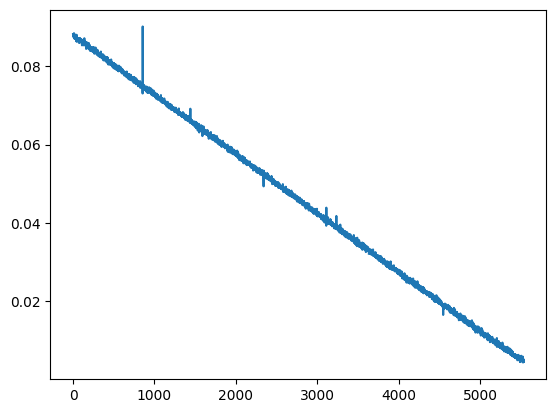

In [53]:
import matplotlib.pyplot as plt

plt.plot(err)

In [21]:
import numpy as np
import random

def relu(x):
    if x > 0:
        return x
    else:
        return 0
    
def custom_mod(a, b):
    # 模拟c++中的mod运算，即余数符号与a相同
    result = a % b
    if a < 0:
        result -= b
    return result
    
def test_unit(x):
    R = 128
    R_rec = 1 / R
    
    y = custom_mod(x * R, 13)
    if y == 0:
        y += 1
        tag = 1
    else:
        tag = 0
    a = int((x * R) / 13)
    
    z = relu(y)
    r = z * (13*a / y) + z - tag
    r = r * R_rec
    
    return r

x = 0.01

r1 = relu(x)
r2 = test_unit(x)

print("x: {}, real:{}, appr: {}".format(x, r1, r2))

x: 0.01, real:0.01, appr: 0.01


In [107]:
tensor = torch.tensor([0,174702,4])
print(tensor%13)
(tensor == 0).to(torch.float)

tensor([0, 8, 4])


tensor([1., 0., 0.])

In [46]:

# 生成一个[0, 65535]之间的随机整数
random_integer = np.random.randint(0, 65536)

print(random_integer)

62507


In [45]:
np.random.laplace(loc=0, scale=1e-6)

-3.996224209155245e-07

In [18]:
tensor = torch.tensor([0,-1.0,2])
print(torch.erf(tensor))
tensor_enc = crypten.cryptensor(tensor)
print((tensor_enc.erf()).get_plain_text())

tensor([ 0.0000, -0.8427,  0.9953])
tensor([   0.0000,   -0.6081, -175.4813])


In [15]:
# 定义近似 erf 函数的多项式
def approximate_erf(x, order=10):
    """ 使用泰勒级数近似 erf 函数 """
    coeffs = [2 / math.sqrt(math.pi) * (-1)**n / (math.factorial(n) * (2*n + 1)) for n in range(order)]
    terms = [coeffs[n] * x.pow(2 * n + 1) for n in range(order)]
    res = sum(terms)
    print(res.get_plain_text())
    return res

# 加载数据并加密 - 假设 x 和 μ 都是已知的
x = torch.tensor([1.0]) # 示例数据
print(torch.erf(x),torch.relu(x))
mu = torch.tensor([1]) # μ 的值
encrypted_x = crypten.cryptensor(x)
encrypted_mu_x = crypten.cryptensor(mu * x)

# 计算加密的 erf(μx) 的近似值
encrypted_erf_mu_x = approximate_erf(encrypted_mu_x)

# 计算 y = (x + x * erf(μx)) / 2
encrypted_y = (encrypted_x + encrypted_x * encrypted_erf_mu_x) / 2

# 解密结果
decrypted_y = encrypted_y.get_plain_text()
print("Decrypted y:", decrypted_y)

tensor([0.8427]) tensor([1.])
tensor([0.8427])
Decrypted y: tensor([0.9213])


In [ ]:
class ApproxReLU(crypten.nn.Module):
    def __init__(self):
        super(ApproxReLU, self).__init__()
    
    def approx_relu(self, x_enc):
        # step0：实际由可信第三方TTP生成
        R1, R2 = 64, 1
        R1_rec = 1 / R1
        b = np.sqrt(R2 / R1**2)
    
        R1 = crypten.cryptensor(R1,device=x_enc.device)
        R1_rec = crypten.cryptensor(R1_rec,device=x_enc.device)
        R2 = crypten.cryptensor(R2,device=x_enc.device)
        b = crypten.cryptensor(b,device=x_enc.device)
        
        # step1
        xR1 = x_enc * R1
        y = x_enc.square() * R1.square() + R2
        # y = y.detach()
        y = y.get_plain_text()
        
    
        # step2
        a = torch.sqrt(y)
    
        # step3
        z = (xR1 + a) / 2
    
        # step4
        z = z*R1_rec - 0.5*b

        return z
    
    def forward(self, x):
        return self.approx_relu(x)